# Project M2: Exploratory Data Analysis #

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 1. Univariate analysis ###

**Plot the distribution of your target. Plot every numeric feature. Count frequencies for every categorical. Point out skew, multimodality, and anything that looks wrong.**


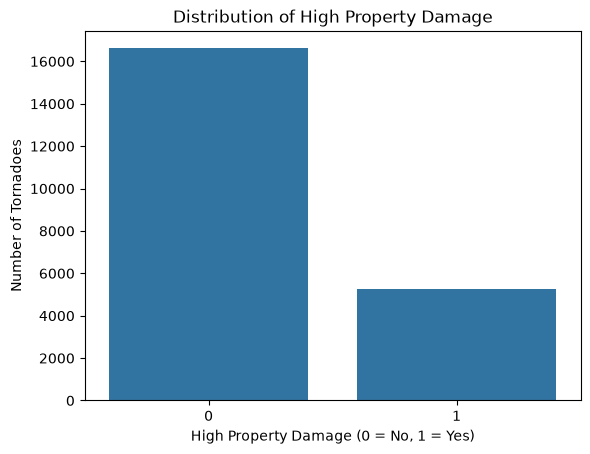

HIGH_PROPERTY_DAMAGE
0    16609
1     5283
Name: count, dtype: int64
HIGH_PROPERTY_DAMAGE
0    75.867897
1    24.132103
Name: proportion, dtype: float64


In [14]:
df.info
df.describe(include="all")
df.columns
target = "HIGH_PROPERTY_DAMAGE"

sns.countplot(data=df, x=target)
plt.title("Distribution of High Property Damage")
plt.xlabel("High Property Damage (0 = No, 1 = Yes)")
plt.ylabel("Number of Tornadoes")
plt.show()

print(df[target].value_counts())
print(df[target].value_counts(normalize=True) * 100)

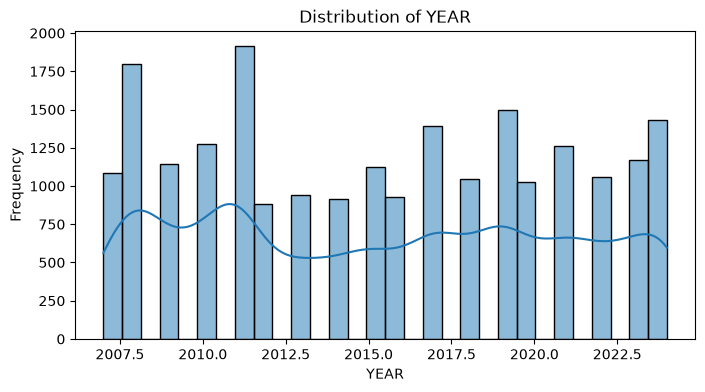

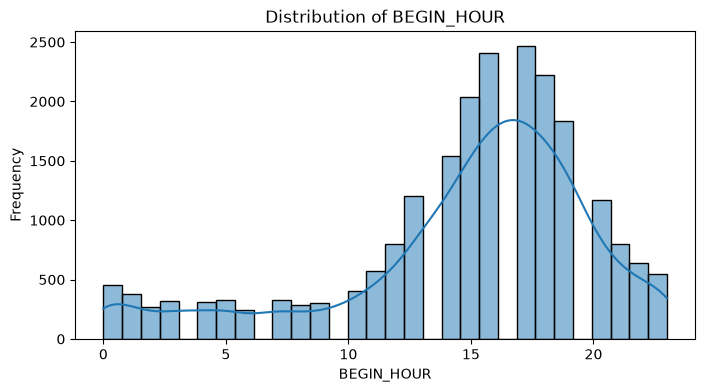

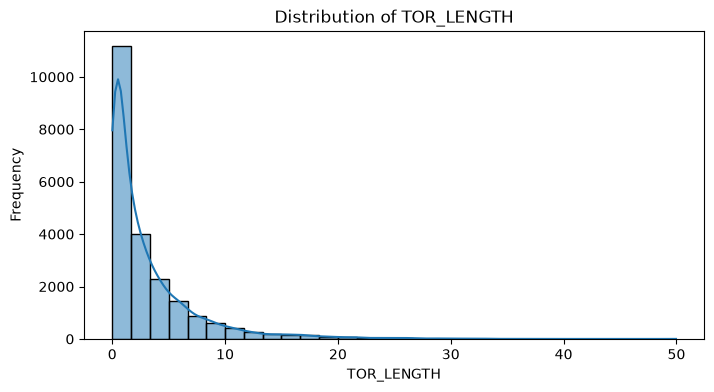

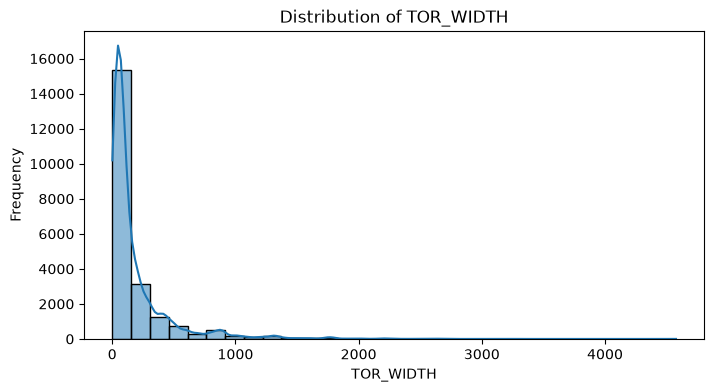

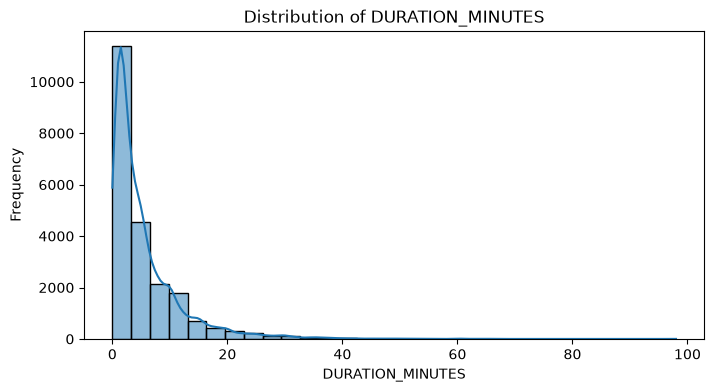

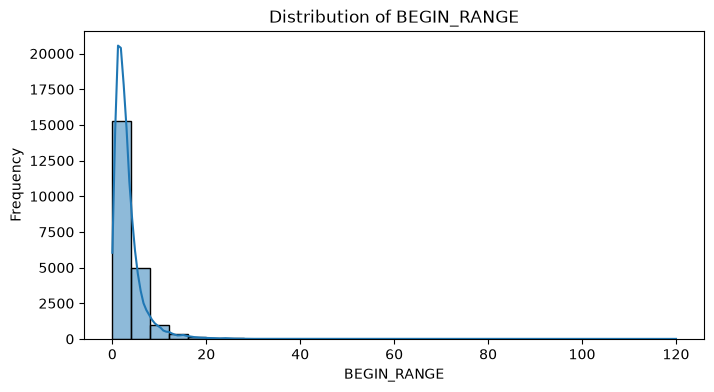

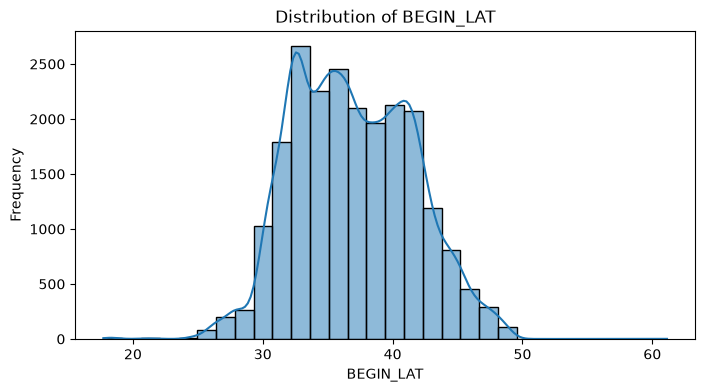

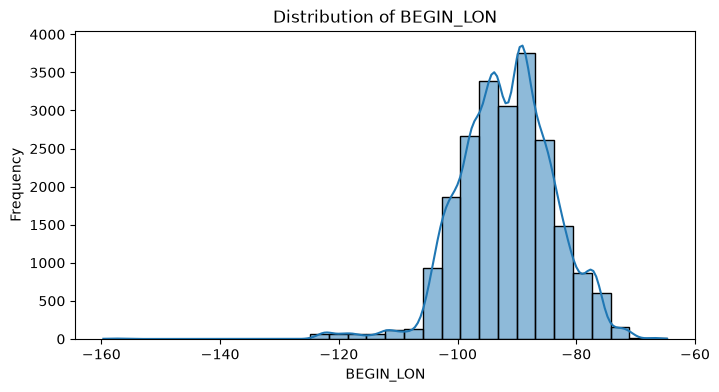

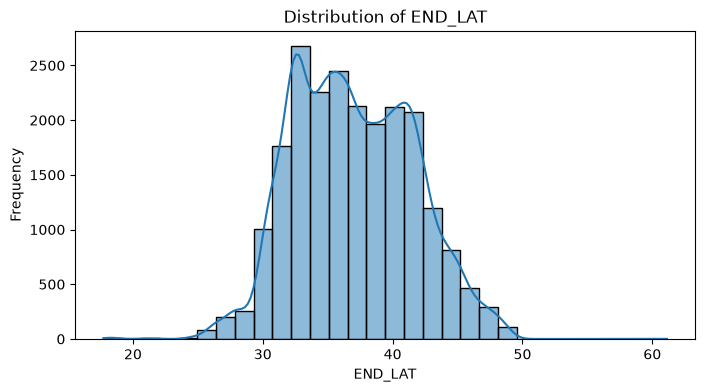

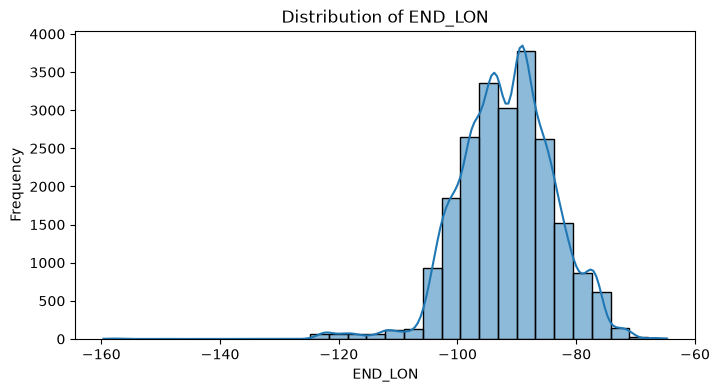

In [15]:
numeric_features = df.select_dtypes(
    include="number"
).columns.drop([
    "HIGH_PROPERTY_DAMAGE",
    "PROPERTY_DAMAGE_USD"
])

for col in numeric_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

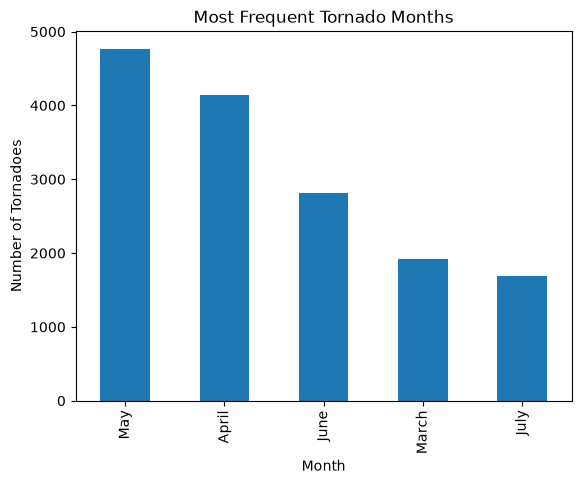

===Tornado Months Frequency===
   MONTH_NAME  Count  Percentage
0         May   4769   21.784213
1       April   4147   18.942993
2        June   2809   12.831171
3       March   1924    8.788599
4        July   1694    7.737986
5      August   1390    6.349351
6     October   1000    4.567879
7    December    933    4.261831
8    February    933    4.261831
9     January    873    3.987758
10   November    720    3.288873
11  September    700    3.197515


In [43]:
month_counts = df["MONTH_NAME"].value_counts().head(5)

month_counts.plot(kind="bar")

plt.title("Most Frequent Tornado Months")
plt.xlabel("Month")
plt.ylabel("Number of Tornadoes")
plt.show()

# table with counts and relative percentages
freq_df = df["MONTH_NAME"].value_counts().reset_index(name='Count')
freq_df['Percentage'] = (freq_df['Count'] / freq_df['Count'].sum()) * 100
print("===Tornado Months Frequency===")

print(freq_df)

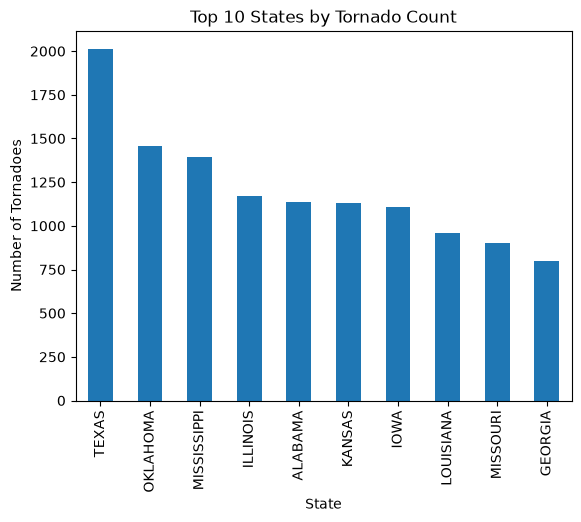

WFO
JAN    1202
OUN     887
SHV     782
BMX     777
TSA     687
       ... 
HFO       6
MFR       4
REV       4
EKA       2
AFC       1
Name: count, Length: 118, dtype: int64

In [29]:
df["STATE"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 States by Tornado Count")
plt.xlabel("State")
plt.ylabel("Number of Tornadoes")
plt.show()
df["WFO"].value_counts()

In [30]:
print("===Complete Counts For All Categorical Features")
for col in ["MONTH_NAME", "STATE", "WFO", "BEGIN_AZIMUTH"]:
    print(df[col].value_counts(dropna=False).to_string())

===Complete Counts For All Categorical Features
MONTH_NAME
May          4769
April        4147
June         2809
March        1924
July         1694
August       1390
October      1000
December      933
February      933
January       873
November      720
September     700
STATE
TEXAS                   2015
OKLAHOMA                1457
MISSISSIPPI             1395
ILLINOIS                1169
ALABAMA                 1137
KANSAS                  1132
IOWA                    1106
LOUISIANA                960
MISSOURI                 904
GEORGIA                  799
ARKANSAS                 782
NEBRASKA                 697
COLORADO                 690
MINNESOTA                676
FLORIDA                  674
TENNESSEE                666
KENTUCKY                 573
OHIO                     569
INDIANA                  557
NORTH CAROLINA           536
WISCONSIN                492
VIRGINIA                 315
NORTH DAKOTA             308
PENNSYLVANIA             298
SOUTH DAKOTA           

In [31]:
df[numeric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
YEAR,21892.0,2015.348164,5.342922,2007.0000,2011.000000,2015.00000,2020.000000,2024.0000
BEGIN_HOUR,21892.0,14.784762,5.334860,0.0000,13.000000,16.00000,18.000000,23.0000
TOR_LENGTH,21892.0,3.153705,4.251419,0.0100,0.480000,1.60000,4.120000,49.9600
TOR_WIDTH,21892.0,189.259737,293.548730,1.0000,50.000000,80.00000,200.000000,4576.0000
DURATION_MINUTES,21892.0,5.495661,6.595529,0.0000,1.000000,3.00000,7.000000,98.0000
BEGIN_RANGE,21892.0,3.261922,3.754346,0.0000,1.000000,2.00000,4.000000,120.0000
BEGIN_LAT,21892.0,36.959077,4.605765,17.7212,33.221500,36.62890,40.530000,61.1300
BEGIN_LON,21892.0,-91.706655,7.879629,-159.6577,-96.918725,-91.55725,-86.571450,-64.7151
END_LAT,21892.0,36.977903,4.602534,17.7212,33.243850,36.64895,40.537700,61.1300
END_LON,21892.0,-91.665930,7.888262,-159.6470,-96.893550,-91.50625,-86.511325,-64.7151


The histograms show that tornado length, width, duration, and beginning range are strongly right-skewed. Most observations are concentrated at smaller values, while a smaller number extend toward much larger values. Tornado start times are concentrated more in the afternoon and early evening, with fewer observations during early morning and daytime hours. The latitude distributions show several smaller peaks, which may indicate some sort of geographic concentration (Tornado Alley) of tornado activity. The longitude distributions are more concentrated though, with a smaller number of observations extending farther west. No clear multimodality is visible in the tornado length, width, duration, or beginning range distributions. However, there are several features that contain unusually large values and need to be investigated further in part 3 outliers. 

### 2. Missingness. ### 
**Quantify how much data each column is missing, then investigate the pattern. Does missingness occur at random, or does it track with the target? Your answer determines what you're allowed to do in M3, so don't skip the investigation.**

In [32]:
missing_data = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percent": df.isnull().mean() * 100
})

missing_data

,Missing Count,Missing Percent
YEAR,0,0.0
MONTH_NAME,0,0.0
BEGIN_HOUR,0,0.0
STATE,0,0.0
WFO,0,0.0
TOR_LENGTH,0,0.0
TOR_WIDTH,0,0.0
DURATION_MINUTES,0,0.0
BEGIN_RANGE,0,0.0
BEGIN_AZIMUTH,0,0.0


Everything comes back as 0, there is no missingness in this dataset. This data comes from the NOAA National Centers for Environmental Data which is the world's largest authority archive for environmental and many other weathe related types of data. This would explain why the dataset doesn't have missing values, but that doesn't mean that there isn't anything in the datsaet that's not worth investigating. 

### 3. Outliers ### 
**Find them, then decide for each whether it's a data error or a real extreme value. State which, and say why. You earn the points for the reasoning, not the decision.**

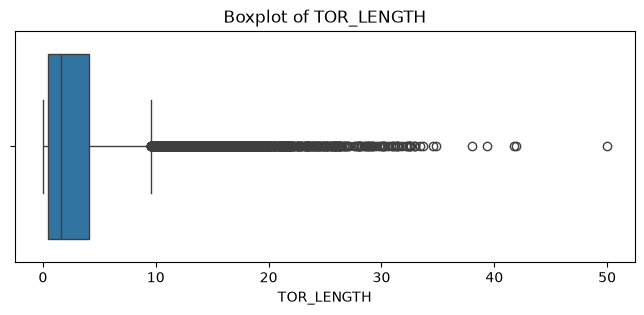

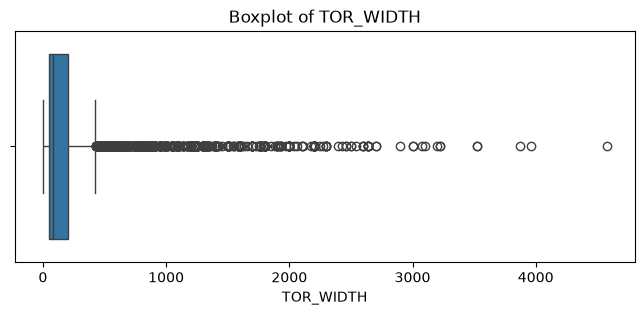

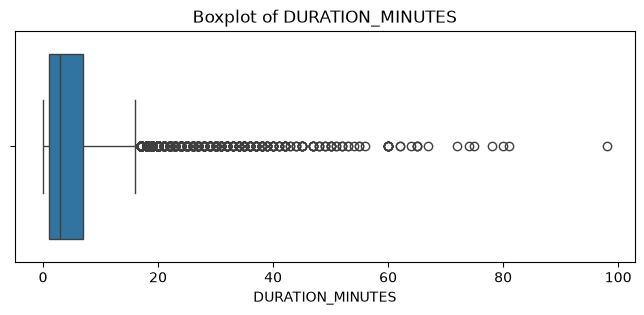

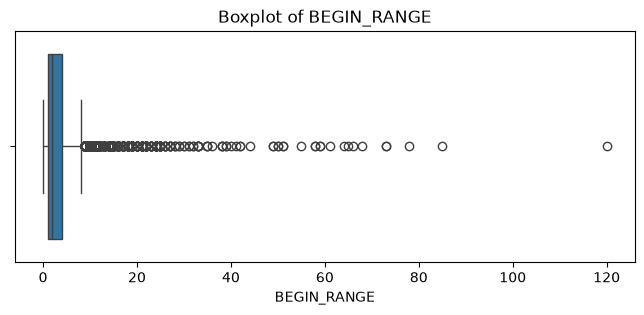

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

columns = [
    "TOR_LENGTH",
    "TOR_WIDTH",
    "DURATION_MINUTES",
    "BEGIN_RANGE"
]

for col in columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [37]:
columns = [
    "TOR_LENGTH",
    "TOR_WIDTH",
    "DURATION_MINUTES",
    "BEGIN_RANGE"
]

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) |
             (df[col] > upper)).sum()

    print(f"{col}: {count} potential outliers")

df.nlargest(10, "TOR_WIDTH")[
    ["YEAR", "STATE", "TOR_WIDTH",
     "HIGH_PROPERTY_DAMAGE"]
]

TOR_LENGTH: 1593 potential outliers
TOR_WIDTH: 2502 potential outliers
DURATION_MINUTES: 1348 potential outliers
BEGIN_RANGE: 1226 potential outliers


,YEAR,STATE,TOR_WIDTH,HIGH_PROPERTY_DAMAGE
8240,2013,OKLAHOMA,4576.0,1
16709,2020,MISSISSIPPI,3960.0,1
950,2007,KANSAS,3872.0,1
2390,2008,WISCONSIN,3520.0,1
16719,2020,MISSISSIPPI,3520.0,1
11197,2016,TEXAS,3221.0,1
11204,2016,TEXAS,3221.0,0
21016,2024,ARKANSAS,3200.0,1
11654,2016,OKLAHOMA,3100.0,1
4491,2010,MISSISSIPPI,3080.0,1


In [38]:
columns = [
    "TOR_LENGTH",
    "TOR_WIDTH",
    "DURATION_MINUTES",
    "BEGIN_RANGE"
]

for col in columns:
    print(f"\nLargest values for {col}:")
    display(
        df.nlargest(5, col)[
            ["YEAR", "STATE", col, "HIGH_PROPERTY_DAMAGE"]
        ]
    )


Largest values for TOR_LENGTH:


,YEAR,STATE,TOR_LENGTH,HIGH_PROPERTY_DAMAGE
21306,2024,LOUISIANA,49.96,1
12442,2017,WISCONSIN,41.88,1
6926,2011,ALABAMA,41.79,1
18002,2021,ALABAMA,39.35,0
6910,2011,NORTH CAROLINA,37.99,1



Largest values for TOR_WIDTH:


,YEAR,STATE,TOR_WIDTH,HIGH_PROPERTY_DAMAGE
8240,2013,OKLAHOMA,4576.0,1
16709,2020,MISSISSIPPI,3960.0,1
950,2007,KANSAS,3872.0,1
2390,2008,WISCONSIN,3520.0,1
16719,2020,MISSISSIPPI,3520.0,1



Largest values for DURATION_MINUTES:


,YEAR,STATE,DURATION_MINUTES,HIGH_PROPERTY_DAMAGE
7089,2011,CALIFORNIA,98,1
18100,2021,COLORADO,81,0
6757,2011,CALIFORNIA,80,1
12442,2017,WISCONSIN,78,1
7927,2012,CALIFORNIA,75,0



Largest values for BEGIN_RANGE:


,YEAR,STATE,BEGIN_RANGE,HIGH_PROPERTY_DAMAGE
9997,2015,OKLAHOMA,120,0
11860,2016,GEORGIA,85,0
18500,2022,KANSAS,78,0
15914,2019,LOUISIANA,73,1
20222,2023,MISSISSIPPI,73,0


In [41]:
zero_duration = df[df["DURATION_MINUTES"] == 0]

print("Zero-duration tornadoes:", len(zero_duration))

print("Zero-duration tornadoes with positive length:",
      (zero_duration["TOR_LENGTH"] > 0).sum())

print("Zero-duration tornadoes with positive width:",
      (zero_duration["TOR_WIDTH"] > 0).sum())

display(
    zero_duration[
        ["YEAR", "STATE", "TOR_LENGTH",
         "TOR_WIDTH", "DURATION_MINUTES",
         "HIGH_PROPERTY_DAMAGE"]
    ].head(10)
)

Zero-duration tornadoes: 1189
Zero-duration tornadoes with positive length: 1189
Zero-duration tornadoes with positive width: 1189


,YEAR,STATE,TOR_LENGTH,TOR_WIDTH,DURATION_MINUTES,HIGH_PROPERTY_DAMAGE
28,2007,NEBRASKA,0.10,20.0,0,0
29,2007,OHIO,0.25,30.0,0,0
35,2007,NEW MEXICO,0.10,20.0,0,0
41,2007,IOWA,0.10,30.0,0,0
61,2007,MISSOURI,0.10,50.0,0,0
62,2007,MISSOURI,0.10,50.0,0,0
64,2007,MISSOURI,0.10,10.0,0,0
88,2007,FLORIDA,0.10,30.0,0,0
115,2007,SOUTH DAKOTA,0.10,50.0,0,0
132,2007,NEBRASKA,0.10,20.0,0,0


**Outliers**

We used the Interquartile Range to identify potential outliers in four of our numeric features: TOR_LENGTH, TOR_WIDTH, DURATION_MINUTES, and BEGIN_RANGE. The analysis identified 1,593 potential outliers in tornado length (7.3%), 2,502 in tornado width (11.4%), 1,348 in duration (6.2%), and 1,226 in beginning range (5.6%).

Tornado Length: The max recorded length is 49.96, compared with a median of 1.60. Four of the five longest tornadoes were associated with high property damage. These values may represent legitimate long-track tornadoes that caused extreme damage rather than data errors.

Tornado Width: The max recorded width is 4,576, compared with a median of 80. All five of the widest tornadoes were associated with high property damage. These observations may also represetn legitimate large tornadoes and contain important information for predicting the target variable.

Tornado Duration: The max duration is 98 minutes, compared with a median of 3 minutes. Long durations may be legitimate, but zero-duration records should also be investigated for possible rounding or recording issues.

Beginning Range: The maximum value is 120, compared with a median of 2. Large beginning-range values may reflect distances from reference locations rather than errors, but their accuracy should be checkedd. We will retain the flagged outliers for now, because there is insufficient evidence that they are data errors. Extreme tornado measurements may represent legitimate severe weather events, and removing them could eliminate useful information for predicting high property damage. Further validation is needed before treating any specific observations as confirmed errors.

**Zero-Duration Observations**

We also identified 1,189 tornadoes (5.4% of the dataset) with a recorded duration of zero minutes. Further investigation showed that all 1,189 observations did have positive tornado lengths and widths. So, this suggests that these observations represent acutal recorded tornado events, despite having zero-minute durations. The zero values may result from rounding or limited time-recording precision rather than incorrect data. We decided to keep these observations because there is insufficient evidence that they are errors. Removing them could result in the loss of legitimate tornado records and potentially useful information for our classification model.

### 4. Bivariate analysis ### 

**Show how each feature relates to the target. Use a correlation matrix for numerics and grouped statistics or boxplots for categoricals. Match the method to the variable type.**

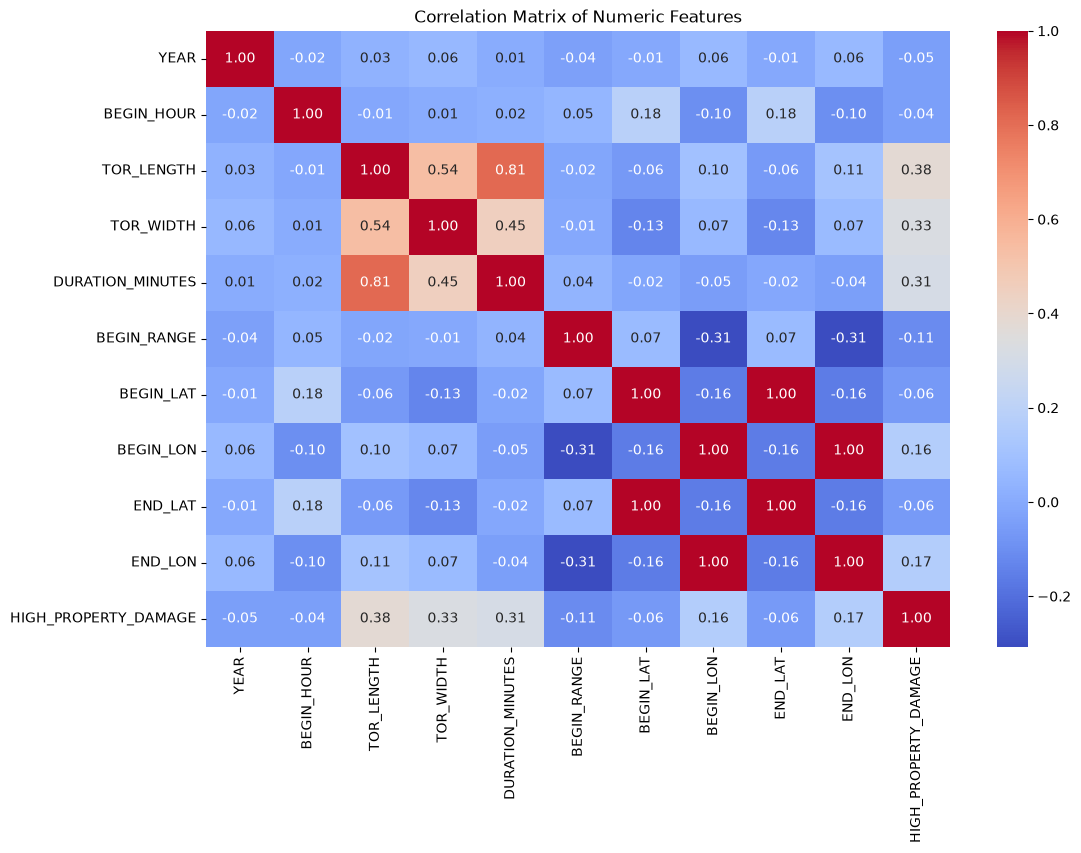

In [44]:
# select numeric columns, except property damage
numeric_df = df.select_dtypes(include="number").drop(
    columns=["PROPERTY_DAMAGE_USD"]
)

# correlation matrix
corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numeric Features")
plt.show()

**Numeric Feature Relationships with High Property Damage**

We created a correlation matrix to look at the relationships between numeric features and our target variable. The strongest positive correlations with the target were tornado length, tornado width, and tornado duration with values of 0.38, 0.33, and 0.31 respectively. These results suggest that longer, wider, and longer-lasting tornadoes tend to be associated with a higher likelihood of causing high property damage. The other features showed weaker relationships with the target. Beginning longitude had a value of 0.16 and ending longitude with a value of 0.17 had weak positive correlations, while beginning range (−0.11) had a weak negative correlation.

We also observed strong correlations between some predictors. Tornado length and duration had a correlation of 0.81, while beginning and ending latitude and longitude were nearly perfectly correlated, but these are both directly related by location so that makes sense. Overall, tornado length, width, and duration appear to be the numeric features that are most strongly associated with high property damage. However, we must remember that correlation does not equal causation.

MONTH_NAME
February     37.084673
December     35.369775
January      33.104238
November     31.388889
March        31.340956
April        29.298288
October      25.400000
September    18.857143
May          18.452506
August       17.482014
July         17.473436
June         16.696333
Name: HIGH_PROPERTY_DAMAGE, dtype: float64


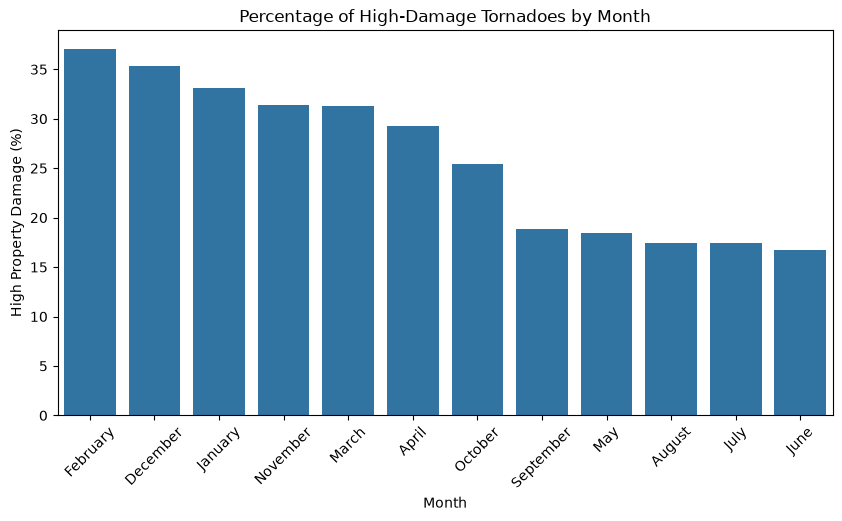

In [46]:
# examine categorical features, starting with month
month_damage = (
    df.groupby("MONTH_NAME")["HIGH_PROPERTY_DAMAGE"]
    .mean()
    .sort_values(ascending=False) * 100
)

print(month_damage)

plt.figure(figsize=(10, 5))
sns.barplot(x=month_damage.index, y=month_damage.values)

plt.title("Percentage of High-Damage Tornadoes by Month")
plt.xlabel("Month")
plt.ylabel("High Property Damage (%)")
plt.xticks(rotation=45)
plt.show()

**Relationship Between Month and High Property Damage**

We grouped tornado observations by month and calculated the percentage classified as high property damage. The graph shows that February had the highest percentage of high-damage tornadoes at approximately 37%, followed by December and January, 35% and 33% respectively. June had the lowest percentage at approximately 17%. An interesting pattern is that winter months generally had higher percentages of high-damage tornadoes, while summer months had lower percentages. This suggests that the month in which a tornado occurs may be associated with its likelihood of causing high property damage however, these percentages won't explain the cause of the relationship, or other factors such as tornado characteristics and geographic location.

,count,damage_percent
STATE,,
TEXAS,2015,21.836228
OKLAHOMA,1457,14.413178
MISSISSIPPI,1395,34.623656
ILLINOIS,1169,15.996578
ALABAMA,1137,19.788918
KANSAS,1132,9.187279
IOWA,1106,18.806510
LOUISIANA,960,29.062500
MISSOURI,904,24.668142


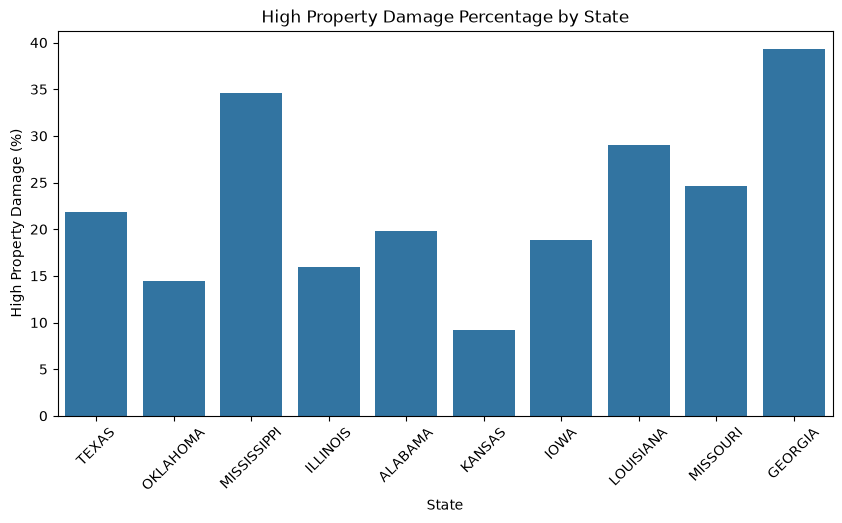

In [48]:
# percentage of high-damage tornadoes among the 10 states with the most tornado observations
state_damage = (
    df.groupby("STATE")["HIGH_PROPERTY_DAMAGE"]
    .agg(["mean", "count"])
)

state_damage["damage_percent"] = state_damage["mean"] * 100

# Select the 10 states with the most tornadoes
top_states = state_damage.nlargest(10, "count")

display(top_states[["count", "damage_percent"]])

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_states.index,
    y=top_states["damage_percent"]
)

plt.title("High Property Damage Percentage by State")
plt.xlabel("State")
plt.ylabel("High Property Damage (%)")
plt.xticks(rotation=45)
plt.show()

**Relationship Between State and High Property Damage**

We graphed the percentage of tornadoes classified as high property damage across the 10 states with the most count of observations. Interestingly enough, Georgia actually had the highest percentage of high-damage tornadoes at approximately 39%, followed by Mississippi (35%) and Louisiana (29%). Kansas had the lowest percentage at approximately 9%, followed by Oklahoma of 14%. These differences suggest that geographic location could be associated with the likelihood of high property damage. But one important thing to remember is that these results don't necessarily indicate differences in tornado strength. There are other factors, such as population density, and infrastructure that could influence the outcomes as well. 

,count,damage_percent
BEGIN_AZIMUTH,,
WSW,1518,27.733860
WNW,1421,27.445461
SW,1662,27.316486
SSW,1491,25.821596
SSE,1286,25.583204
NW,1395,24.731183
ESE,1091,24.197984
S,1703,24.075161
W,1743,23.924269


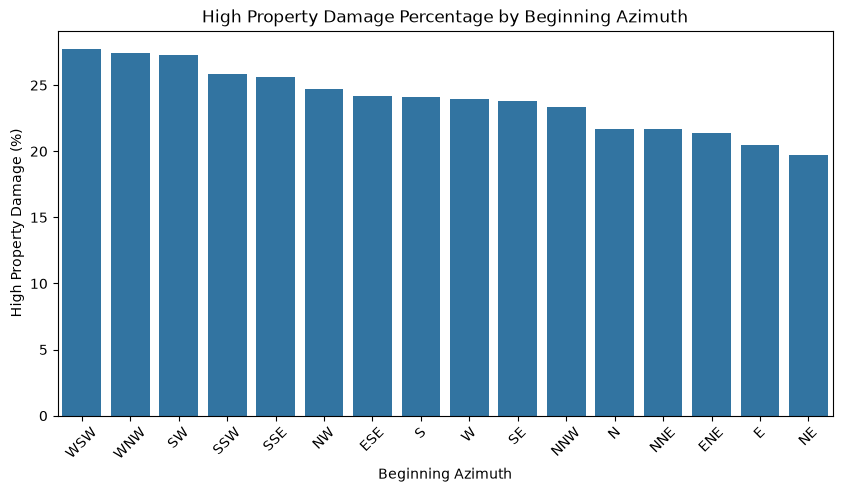

In [50]:
# now we look at BEGIN_AZIMUTH
azimuth_damage = (
    df.groupby("BEGIN_AZIMUTH")["HIGH_PROPERTY_DAMAGE"]
    .agg(["mean", "count"])
)

azimuth_damage["damage_percent"] = (
    azimuth_damage["mean"] * 100
)

azimuth_damage = azimuth_damage.sort_values(
    "damage_percent",
    ascending=False
)

display(azimuth_damage[["count", "damage_percent"]])

plt.figure(figsize=(10, 5))

sns.barplot(
    x=azimuth_damage.index,
    y=azimuth_damage["damage_percent"]
)

plt.title("High Property Damage Percentage by Beginning Azimuth")
plt.xlabel("Beginning Azimuth")
plt.ylabel("High Property Damage (%)")
plt.xticks(rotation=45)
plt.show()

**Relationship Between Beginning Azimuth and High Property Damage**

We grouped tornado observations by BEGIN_AZIMUTH and calculated the percentage associated with high property damage. The highest percentage was for WSW at approx 28%, then WNW and SW, both approx 27%. NE had the lowest percentage at approx 20%. The differences between compass directions were relatively small compared with the differences observed across states and months with only an 8% difference. From these results we can see that beginning azimuth may have a relationship with high property damage, but the association is pretty weak. The direction only represents the tornado's starting location relative to a reference point, so not necessarily its complete direction.

,count,damage_percent
WFO,,
JAN,1202,34.858569
OUN,887,10.484780
SHV,782,27.877238
BMX,777,15.958816
PAH,687,33.478894
TSA,687,22.561863
DMX,672,19.494048
FFC,535,42.429907
MPX,511,20.743640


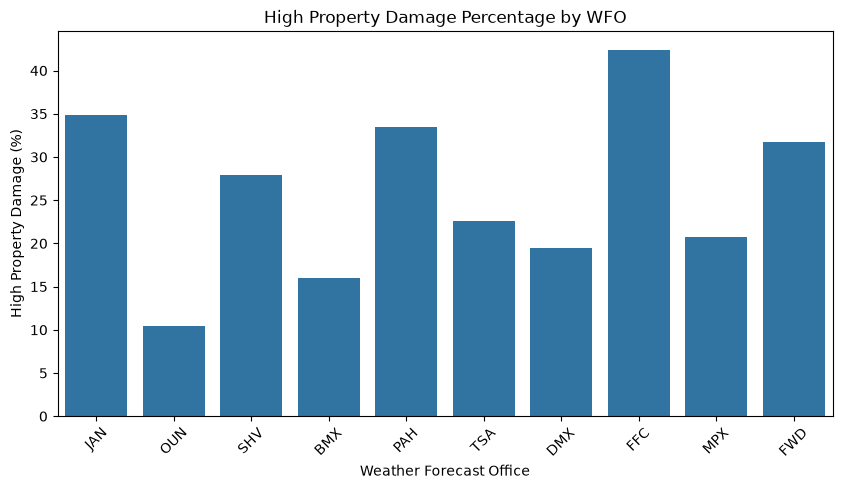

In [51]:
wfo_damage = (
    df.groupby("WFO")["HIGH_PROPERTY_DAMAGE"]
    .agg(["mean", "count"])
)

wfo_damage["damage_percent"] = wfo_damage["mean"] * 100

# Select 10 WFOs with the most observations
top_wfos = wfo_damage.nlargest(10, "count")

display(top_wfos[["count", "damage_percent"]])

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_wfos.index,
    y=top_wfos["damage_percent"]
)

plt.title("High Property Damage Percentage by WFO")
plt.xlabel("Weather Forecast Office")
plt.ylabel("High Property Damage (%)")
plt.xticks(rotation=45)
plt.show()

**Relationship Between WFO and High Property Damage**

We examined the ten Weather Forecast Offices (WFOs) with the most tornado observations and calculated the percentage of tornadoes associated with high property damage. FFC had the highest percentage at approximately 42%, followed by JAN 35%, and PAH 34%. OUN had the lowest percentage at only approx 11%. These results suggest that high property damage rates do vary across Weather Forecast Offices. Because WFO represents geographic regions, these differences may be related to location, population density, infrastructure, or other tornado characteristics rather than the offices themselves. Further analysis would be needed to understand the reasons for these differences and whether WFO has an actual influence over the target variable.

**Question 4 Summary**

We examined the relationships between the numeric and categorical features and our target variable, HIGH_PROPERTY_DAMAGE. Tornado length, width, and duration had the strongest positive correlations with high property damage. From this, we can hypothesize that larger and longer-lasting tornadoes tend to be associated with a greater likelihood of high property damage. We observed differences in high property damage percentages across months, states, beginning azimuth directions, and Weather Forecast Offices. February had the highest high-damage percentage among months, while June had the lowest. Among the ten most frequently observed states, Georgia had the highest percentage and Kansas had the lowest. Beginning azimuth showed smaller differences, with percentages ranging from approximately 20% to 28%. WFO showed larger differences, ranging from approximately 11% for OUN to 42% for FFC. Overall, tornado length, width, and duration showed the strongest linear relationships with the target among numeric features. Geographic and seasonal categories also showed differences in high-damage rates.

### 5. Multicollinearity ### 

**Flag any feature pair correlated above 0.8. This will matter for the linear models you fit in M4.**


In [52]:
# Numeric predictors only (exclude target and leakage column)
numeric_features = df.select_dtypes(include="number").drop(
    columns=["HIGH_PROPERTY_DAMAGE", "PROPERTY_DAMAGE_USD"]
)

corr = numeric_features.corr()

# Find pairs with absolute correlation greater than 0.8
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        value = corr.iloc[i, j]

        if abs(value) > 0.8:
            print(
                f"{corr.columns[i]} and {corr.columns[j]}: "
                f"{value:.4f}"
            )

TOR_LENGTH and DURATION_MINUTES: 0.8123
BEGIN_LAT and END_LAT: 1.0000
BEGIN_LON and END_LON: 1.0000


**Question 5 Summary**

We examined the correlations between numeric predictor features to identify potential multicollinearity. This was actually already discovered in the previous section 4, the heatmap titled "Correlation Matrix of Numeric Features"

Three feature pairs had absolute correlations greater than 0.8:

- TOR_LENGTH and DURATION_MINUTES: 0.8123
- BEGIN_LAT and END_LAT: 1.0000
- BEGIN_LON and END_LON: 1.0000

The strong correlation between tornado length and duration suggests that longer tornadoes generally have longer durations. The beginning and ending latitude and longitude features are almost perfectly correlated, because they more than likely contain overlapping geographic info. These relationships could definitely cause multicollinearity in future linear models, making it more difficult to interpret individual coefficients. We will consider removing redundant features or applying regularization during model development but no features have been removed yet.

### 6. Leakage check ### 

**Examine whether any feature encodes information you wouldn't have at prediction time. Say what you checked and what you concluded — even if you found nothing. A feature that leaks will make your M4 results look excellent and mean nothing.**


In [53]:
# checking whether the target matches the $100,000 damage threshold

damage_target = (
    df["PROPERTY_DAMAGE_USD"] >= 100000
).astype(int)

matches = (
    damage_target == df["HIGH_PROPERTY_DAMAGE"]
).mean() * 100

print(f"Target agreement: {matches:.2f}%")

Target agreement: 100.00%


**Question 6 Summary**

We examined the dataset for potential data leakage by identifying features that might contain information we don't have at prediction time. PROPERTY_DAMAGE_USD was identified as a direct source of data leakage because our target variable is determined by whether property damage reaches $100,000. Just to verify, we compared the target variable against a classification created using PROPERTY_DAMAGE_USD >= 100000. The results showed 100% agreement across all observations, which confirms that the damage amount determines the target. Confirming this, we will exclude PROPERTY_DAMAGE_USD from our predictive features to prevent data leakage. We also identified tornado length, width, duration, and ending coordinates as potential timing-related leakage concerns. These features may not be available before a tornado ends, so their suitability depends on when the model is intended to make predictions before or after the event.

### 7. Metric commitment ### 
**Name the metric you'll optimize in M4 and defend why it fits this problem. Tie it back to the error costs you described in M1 — if you said false negatives hurt more, your metric should reflect that. Accuracy rarely works on imbalanced data; if you choose it, argue for it.**


We plan to optimize the F1-score for the high-property-damage class. Our dataset is imbalanced, with approximately 75.9% of tornadoes classified as low property damage and 24.1% classified as high property damage. Because of this imbalance, accuracy alone would not be a reliable measure of model performance. A model that always predicts low property damage could achieve 75.9% accuracy without correctly identifying any high-damage tornadoes. We selected F1-score because it balances precision and recall, both important metrics. Precision measures how often our high-damage predictions are correct, while recall measures how many actual high-damage tornadoes our model successfully identifies. Both false positives and false negatives are important in our project. False positives could incorrectly classify tornadoes as causing significant damage, while false negatives could cause us to miss tornadoes that actually caused significant damage. Since we have not established that one type of error is more costly than the other, F1-score provides a reasonable balance between the two. We will use the F1-score for the positive class HIGH_PROPERTY_DAMAGE = 1 as our primary evaluation metric in M4.

### 8. Five findings ### 

**List what you actually learned, numbered, one sentence each. Every finding must state a specific implication for how you'll preprocess or model in M3. "The data has missing values" is not a finding. "Income is missing for 22% of rows, and those rows skew toward the positive class, so I'll add a missingness indicator rather than drop them" is.**

1. **Class Imbalance:** Our target is imbalanced, with 75.9% low-damage and 24.1% high-damage tornadoes, so we will use stratified train-test splitting and prioritize F1-score over accuracy when evaluating our models.

2. **Outliers:** Tornado length, width, and duration contain many potential outliers that may represent legitimate severe tornado events, so we will save these observations unless there is evidence of data errors.

3. **Multicollinearity:** Tornado length and duration have a correlation of 0.8123, while beginning and ending coordinates have correlations near 1.0, so we will consider removing these redundant predictors or using regularization when building linear models.

4. **Data Leakage:** PROPERTY_DAMAGE_USD reproduces our target with 100% agreement, so we will exclude this feature from model training to prevent the model from using the answer as a predictor.

5. **Categorical Relationships:** High-property-damage percentages vary across months, states, and WFOs, so we will encode categorical features and evaluate whether geographic and seasonal information improves model performance.